In [1]:
pip install librosa

Note: you may need to restart the kernel to use updated packages.


Zip size (bytes): 182082353
Extraction completed.
Classes: ['down', 'go', 'left', 'no', 'right', 'stop', 'up', 'yes']
Number of classes: 8


C:\Users\RU-ECE-118-11\anaconda3\lib\site-packages\paramiko\pkey.py:82: CryptographyDeprecationWarning: TripleDES has been moved to cryptography.hazmat.decrepit.ciphers.algorithms.TripleDES and will be removed from cryptography.hazmat.primitives.ciphers.algorithms in 48.0.0.
  "cipher": algorithms.TripleDES,
C:\Users\RU-ECE-118-11\anaconda3\lib\site-packages\paramiko\transport.py:219: CryptographyDeprecationWarning: Blowfish has been moved to cryptography.hazmat.decrepit.ciphers.algorithms.Blowfish and will be removed from cryptography.hazmat.primitives.ciphers.algorithms in 45.0.0.
  "class": algorithms.Blowfish,
C:\Users\RU-ECE-118-11\anaconda3\lib\site-packages\paramiko\transport.py:243: CryptographyDeprecationWarning: TripleDES has been moved to cryptography.hazmat.decrepit.ciphers.algorithms.TripleDES and will be removed from cryptography.hazmat.primitives.ciphers.algorithms in 48.0.0.
  "class": algorithms.TripleDES,


X shape: (800, 32, 40)
y shape: (800,)
Model: "sequential"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 lstm (LSTM)                 (None, 64)                26880     
                                                                 
 dropout (Dropout)           (None, 64)                0         
                                                                 
 dense (Dense)               (None, 32)                2080      
                                                                 
 dense_1 (Dense)             (None, 8)                 264       
                                                                 
Total params: 29224 (114.16 KB)
Trainable params: 29224 (114.16 KB)
Non-trainable params: 0 (0.00 Byte)
_________________________________________________________________
Epoch 1/15
20/20 [==============================] - 2s 27ms/step - loss: 2.0930 - accuracy: 0.1484 - val_loss: 

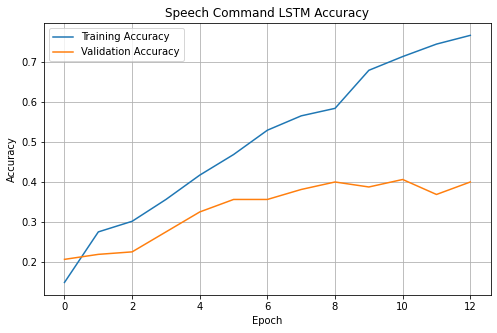

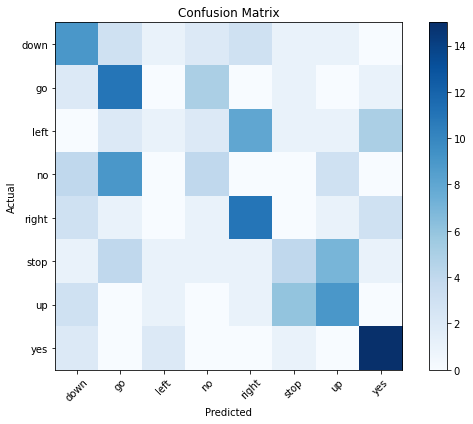

              precision    recall  f1-score   support

        down       0.38      0.45      0.41        20
          go       0.37      0.55      0.44        20
        left       0.17      0.05      0.08        20
          no       0.27      0.20      0.23        20
       right       0.46      0.55      0.50        20
        stop       0.29      0.20      0.24        20
          up       0.41      0.45      0.43        20
         yes       0.60      0.75      0.67        20

    accuracy                           0.40       160
   macro avg       0.37      0.40      0.37       160
weighted avg       0.37      0.40      0.37       160



In [2]:
import os
import zipfile
import random
import librosa
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import LabelEncoder
from sklearn.model_selection import train_test_split
from sklearn.metrics import confusion_matrix, classification_report
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import LSTM, Dense, Dropout
from tensorflow.keras.callbacks import EarlyStopping

# Reproducibility
random.seed(42)
np.random.seed(42)
tf.random.set_seed(42)

# 1. Extract dataset if needed
zip_path = r"C:\dl\mini_speech_commands.zip"
extract_dir = r"C:\dl\mini_speech_commands"

if os.path.exists(zip_path):
    print("Zip size (bytes):", os.path.getsize(zip_path))
    os.makedirs(extract_dir, exist_ok=True)
    with zipfile.ZipFile(zip_path, "r") as zip_ref:
        zip_ref.extractall(extract_dir)
    print("Extraction completed.")

# Handle nested folder if present
nested_path = os.path.join(extract_dir, "mini_speech_commands")
dataset_path = nested_path if os.path.isdir(nested_path) else extract_dir

commands = sorted([
    d for d in os.listdir(dataset_path)
    if os.path.isdir(os.path.join(dataset_path, d))
])
print("Classes:", commands)
print("Number of classes:", len(commands))


# 2. Extract fixed-length MFCC frame sequence: shape (max_len, n_mfcc)
def extract_mfcc_sequence(file_path, sr=16000, n_mfcc=40, max_len=32):
    try:
        audio, sample_rate = librosa.load(file_path, sr=sr)
        mfcc = librosa.feature.mfcc(y=audio, sr=sample_rate, n_mfcc=n_mfcc)  # (40, frames)
        mfcc = mfcc.T  # (frames, 40)

        if len(mfcc) < max_len:
            mfcc = np.pad(mfcc, ((0, max_len - len(mfcc)), (0, 0)), mode="constant")
        else:
            mfcc = mfcc[:max_len]

        return mfcc.astype(np.float32)
    except Exception as e:
        print(f"Error processing {file_path}: {e}")
        return None


samples_per_class = 100
max_len = 32
n_mfcc = 40

X_list, y_list = [], []

for command in commands:
    folder = os.path.join(dataset_path, command)
    wav_files = [f for f in os.listdir(folder) if f.endswith(".wav")]
    random.shuffle(wav_files)
    selected_files = wav_files[:samples_per_class]

    for file_name in selected_files:
        file_path = os.path.join(folder, file_name)
        seq = extract_mfcc_sequence(file_path, sr=16000, n_mfcc=n_mfcc, max_len=max_len)
        if seq is not None:
            X_list.append(seq)
            y_list.append(command)

X = np.array(X_list, dtype=np.float32)  # (N, max_len, 40)
y_raw = np.array(y_list)

print("X shape:", X.shape)
print("y shape:", y_raw.shape)

# 3. Encode labels and split
label_encoder = LabelEncoder()
y = label_encoder.fit_transform(y_raw)

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y,
)

# Normalize features using training-set mean/std per MFCC bin
mean = X_train.mean(axis=(0, 1), keepdims=True)
std = X_train.std(axis=(0, 1), keepdims=True) + 1e-8
X_train = (X_train - mean) / std
X_test = (X_test - mean) / std

# 4. Build and train LSTM
speech_model = Sequential([
    LSTM(64, input_shape=(max_len, n_mfcc)),
    Dropout(0.3),
    Dense(32, activation="relu"),
    Dense(len(label_encoder.classes_), activation="softmax"),
])

speech_model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"],
)
speech_model.summary()

early_stop = EarlyStopping(
    monitor="val_loss",
    patience=4,
    restore_best_weights=True,
)

history = speech_model.fit(
    X_train,
    y_train,
    validation_data=(X_test, y_test),
    epochs=15,
    batch_size=32,
    callbacks=[early_stop],
    verbose=1,
)

test_loss, test_acc = speech_model.evaluate(X_test, y_test, verbose=0)
print(f"Test Loss: {test_loss:.4f} | Test Accuracy: {test_acc:.4f}")

# 5. Plot accuracy curve
plt.figure(figsize=(8, 5))
plt.plot(history.history["accuracy"], label="Training Accuracy")
plt.plot(history.history["val_accuracy"], label="Validation Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("Speech Command LSTM Accuracy")
plt.legend()
plt.grid(True)
plt.show()

# 6. Confusion matrix and classification report
y_pred = np.argmax(speech_model.predict(X_test, verbose=0), axis=1)

cm = confusion_matrix(y_test, y_pred)
plt.figure(figsize=(8, 6))
plt.imshow(cm, cmap="Blues")
plt.colorbar()
plt.xticks(range(len(label_encoder.classes_)), label_encoder.classes_, rotation=45)
plt.yticks(range(len(label_encoder.classes_)), label_encoder.classes_)
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix")
plt.tight_layout()
plt.show()

print(classification_report(y_test, y_pred, target_names=label_encoder.classes_))